#### Data analysis and EDA

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns

In [2]:
df = pd.read_csv('survey.csv')
df.head()

,Timestamp,Age,Gender,Country,state,self_employed,family_history,treatment,work_interfere,no_employees,...,leave,mental_health_consequence,phys_health_consequence,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence,comments
0,2014-08-27 11:29:31,37,Female,United States,IL,NaN,No,Yes,Often,6-25,...,Somewhat easy,No,No,Some of them,Yes,No,Maybe,Yes,No,NaN
1,2014-08-27 11:29:37,44,M,United States,IN,NaN,No,No,Rarely,More than 1000,...,Don't know,Maybe,No,No,No,No,No,Don't know,No,NaN
2,2014-08-27 11:29:44,32,Male,Canada,NaN,NaN,No,No,Rarely,6-25,...,Somewhat difficult,No,No,Yes,Yes,Yes,Yes,No,No,NaN
3,2014-08-27 11:29:46,31,Male,United Kingdom,NaN,NaN,Yes,Yes,Often,26-100,...,Somewhat difficult,Yes,Yes,Some of them,No,Maybe,Maybe,No,Yes,NaN
4,2014-08-27 11:30:22,31,Male,United States,TX,NaN,No,No,Never,100-500,...,Don't know,No,No,Some of them,Yes,Yes,Yes,Don't know,No,NaN


In [3]:
df.shape

(1259, 27)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1259 entries, 0 to 1258
Data columns (total 27 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   Timestamp                  1259 non-null   object
 1   Age                        1259 non-null   int64 
 2   Gender                     1259 non-null   object
 3   Country                    1259 non-null   object
 4   state                      744 non-null    object
 5   self_employed              1241 non-null   object
 6   family_history             1259 non-null   object
 7   treatment                  1259 non-null   object
 8   work_interfere             995 non-null    object
 9   no_employees               1259 non-null   object
 10  remote_work                1259 non-null   object
 11  tech_company               1259 non-null   object
 12  benefits                   1259 non-null   object
 13  care_options               1259 non-null   object
 14  wellness

In [5]:
df.describe() 

,Age
count,1.259000e+03
mean,7.942815e+07
std,2.818299e+09
min,-1.726000e+03
25%,2.700000e+01
50%,3.100000e+01
75%,3.600000e+01
max,1.000000e+11


### cleaning age column: 
convert outliers in age column to null values, then take count of null values and then delete null rows compltely.

In [6]:
df.loc[(df['Age'] < 18) | (df['Age'] > 100), 'Age'] = np.nan

In [7]:
df['Age'].isnull().sum() #8 null values

np.int64(8)

In [8]:
df.dropna(subset=['Age'], inplace=True) #deleting null value rows.

In [9]:
df['Age'].isnull().sum() #0 null values 

np.int64(0)

### cleaning gender column

In [10]:
df['Gender'].value_counts()

Gender
Male                                              612
male                                              204
Female                                            121
M                                                 116
female                                             62
F                                                  38
m                                                  34
f                                                  15
Make                                                4
Woman                                               3
Male                                                3
Female                                              2
Cis Male                                            2
Man                                                 2
Female (trans)                                      2
something kinda male?                               1
Trans-female                                        1
Cis Female                                          1
Male-ish             

In [11]:
#convert gender column to lowercase
df['Gender'] = df['Gender'].str.lower()

# 2 classify Male, Female, Other to 3 different group.
def clean_gender(val):
    if 'm' in val and 'fe' not in val and 'trans' not in val and 'something' not in val:
        return 'Male'
    elif 'f' in val and 'trans' not in val:
        return 'Female'
    else:
        return 'Other/Non-Binary'    
df['Gender'] = df['Gender'].apply(clean_gender)


# 3.count gender column value
df['Gender'].value_counts()

Gender
Male                992
Female              244
Other/Non-Binary     15
Name: count, dtype: int64

In [12]:
df

,Timestamp,Age,Gender,Country,state,self_employed,family_history,treatment,work_interfere,no_employees,...,leave,mental_health_consequence,phys_health_consequence,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence,comments
0,2014-08-27 11:29:31,37.0,Female,United States,IL,NaN,No,Yes,Often,6-25,...,Somewhat easy,No,No,Some of them,Yes,No,Maybe,Yes,No,NaN
1,2014-08-27 11:29:37,44.0,Male,United States,IN,NaN,No,No,Rarely,More than 1000,...,Don't know,Maybe,No,No,No,No,No,Don't know,No,NaN
2,2014-08-27 11:29:44,32.0,Male,Canada,NaN,NaN,No,No,Rarely,6-25,...,Somewhat difficult,No,No,Yes,Yes,Yes,Yes,No,No,NaN
3,2014-08-27 11:29:46,31.0,Male,United Kingdom,NaN,NaN,Yes,Yes,Often,26-100,...,Somewhat difficult,Yes,Yes,Some of them,No,Maybe,Maybe,No,Yes,NaN
4,2014-08-27 11:30:22,31.0,Male,United States,TX,NaN,No,No,Never,100-500,...,Don't know,No,No,Some of them,Yes,Yes,Yes,Don't know,No,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1254,2015-09-12 11:17:21,26.0,Male,United Kingdom,NaN,No,No,Yes,NaN,26-100,...,Somewhat easy,No,No,Some of them,Some of them,No,No,Don't know,No,NaN
1255,2015-09-26 01:07:35,32.0,Male,United States,IL,No,Yes,Yes,Often,26-100,...,Somewhat difficult,No,No,Some of them,Yes,No,No,Yes,No,NaN
1256,2015-11-07 12:36:58,34.0,Male,United States,CA,No,Yes,Yes,Sometimes,More than 1000,...,Somewhat difficult,Yes,Yes,No,No,No,No,No,No,NaN
1257,2015-11-30 21:25:06,46.0,Female,United States,NC,No,No,No,NaN,100-500,...,Don't know,Yes,No,No,No,No,No,No,No,NaN


### Null value handling

In [13]:
df.isnull().sum()

Timestamp                       0
Age                             0
Gender                          0
Country                         0
state                         513
self_employed                  18
family_history                  0
treatment                       0
work_interfere                262
no_employees                    0
remote_work                     0
tech_company                    0
benefits                        0
care_options                    0
wellness_program                0
seek_help                       0
anonymity                       0
leave                           0
mental_health_consequence       0
phys_health_consequence         0
coworkers                       0
supervisor                      0
mental_health_interview         0
phys_health_interview           0
mental_vs_physical              0
obs_consequence                 0
comments                     1090
dtype: int64

In [14]:
df.drop(columns=['comments'], inplace=True) # droping column "comments"

In [15]:
df.isnull().sum()

Timestamp                      0
Age                            0
Gender                         0
Country                        0
state                        513
self_employed                 18
family_history                 0
treatment                      0
work_interfere               262
no_employees                   0
remote_work                    0
tech_company                   0
benefits                       0
care_options                   0
wellness_program               0
seek_help                      0
anonymity                      0
leave                          0
mental_health_consequence      0
phys_health_consequence        0
coworkers                      0
supervisor                     0
mental_health_interview        0
phys_health_interview          0
mental_vs_physical             0
obs_consequence                0
dtype: int64

In [16]:
df.drop(columns=['state'], inplace=True) #droping column "state'

In [17]:
df['work_interfere'] = df['work_interfere'].fillna('Unknown')

In [18]:
df.isnull().sum()

Timestamp                     0
Age                           0
Gender                        0
Country                       0
self_employed                18
family_history                0
treatment                     0
work_interfere                0
no_employees                  0
remote_work                   0
tech_company                  0
benefits                      0
care_options                  0
wellness_program              0
seek_help                     0
anonymity                     0
leave                         0
mental_health_consequence     0
phys_health_consequence       0
coworkers                     0
supervisor                    0
mental_health_interview       0
phys_health_interview         0
mental_vs_physical            0
obs_consequence               0
dtype: int64

In [19]:
df['self_employed'] = df['self_employed'].fillna(df['self_employed'].mode()[0])

In [20]:
df.isnull().sum().sum()

np.int64(0)

### EDA & Visualization

#### univariate analysis

In [21]:
df['Age'].describe()

count    1251.000000
mean       32.076739
std         7.288272
min        18.000000
25%        27.000000
50%        31.000000
75%        36.000000
max        72.000000
Name: Age, dtype: float64

In [22]:
df['Age'].median()

np.float64(31.0)

In [23]:
import matplotlib.pyplot as plt
%matplotlib inline

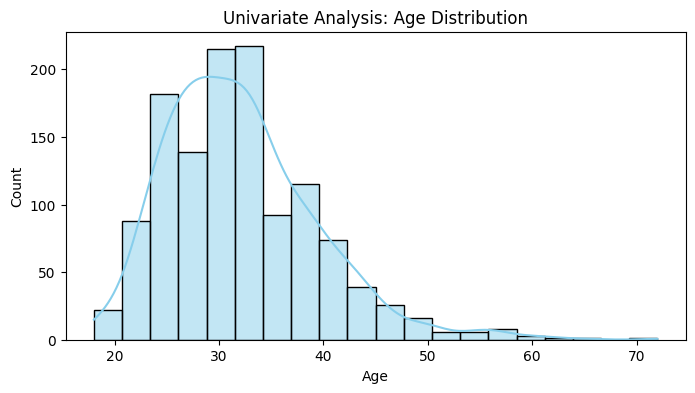

In [24]:
# 2. Histogram & KDE Plot
plt.figure(figsize=(8, 4))
sns.histplot(df['Age'], bins=20, kde=True, color='skyblue')
plt.title('Univariate Analysis: Age Distribution')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

In [25]:
print(df['Gender'].value_counts())

Gender
Male                992
Female              244
Other/Non-Binary     15
Name: count, dtype: int64


C:\Users\hp\AppData\Local\Temp\ipykernel_13584\919159045.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Gender', palette='Set2')


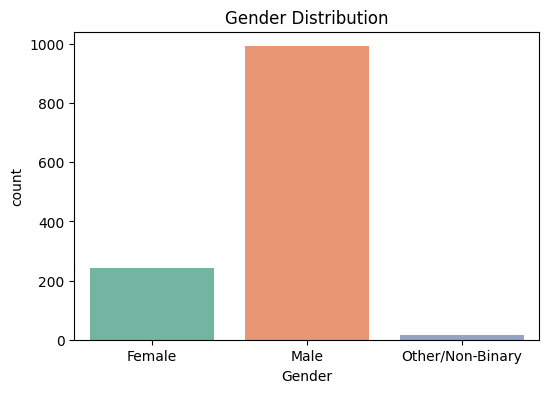

In [26]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Gender', palette='Set2')
plt.title('Gender Distribution')
plt.show()

C:\Users\hp\AppData\Local\Temp\ipykernel_13584\1389289572.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='family_history', palette='Set1')


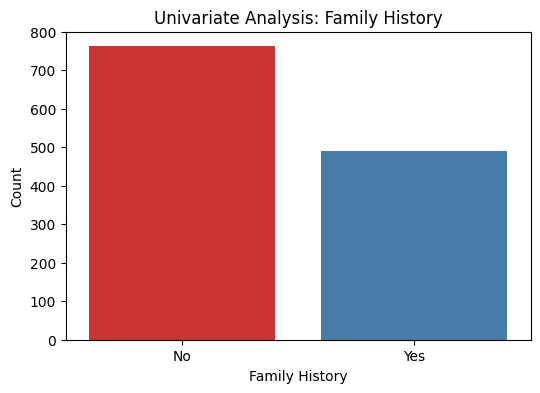

In [27]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='family_history', palette='Set1')
plt.title('Univariate Analysis: Family History')
plt.xlabel('Family History')
plt.ylabel('Count')
plt.show()

### Bivariate analysis

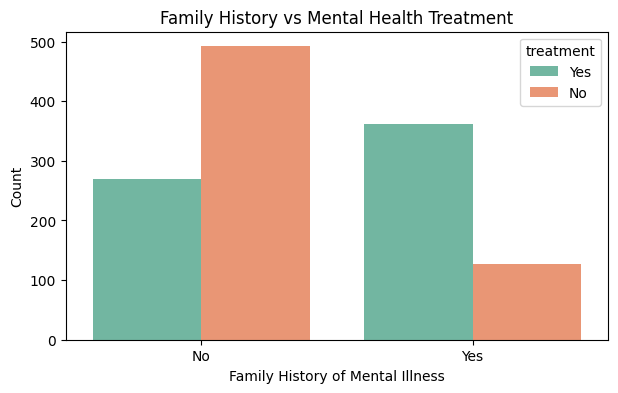

In [28]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='family_history', hue='treatment', palette='Set2')
plt.title('Family History vs Mental Health Treatment')
plt.xlabel('Family History of Mental Illness')
plt.ylabel('Count')
plt.show()

In [29]:
import seaborn as sns

<Axes: xlabel='work_interfere', ylabel='count'>

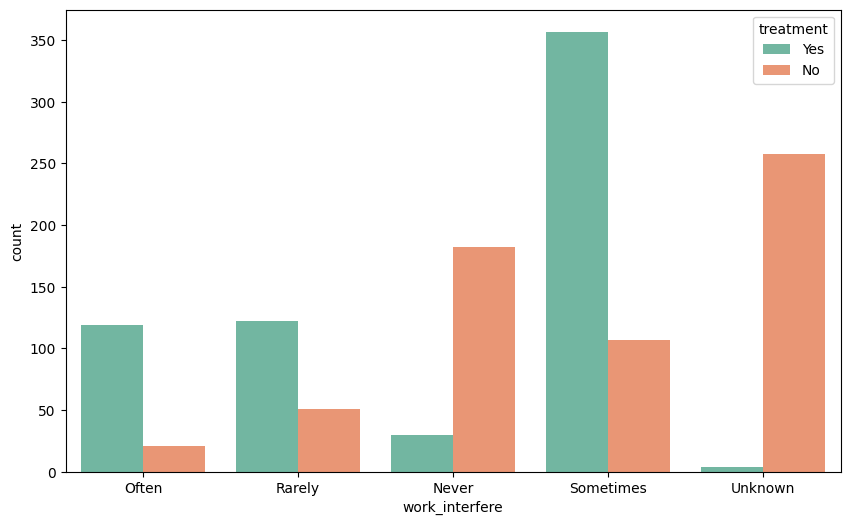

In [31]:
plt.figure(figsize=(10,6))
sns.countplot(x='work_interfere',hue='treatment',data=df,palette='Set2')

### Encoding

In [32]:
df

,Timestamp,Age,Gender,Country,self_employed,family_history,treatment,work_interfere,no_employees,remote_work,...,anonymity,leave,mental_health_consequence,phys_health_consequence,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence
0,2014-08-27 11:29:31,37.0,Female,United States,No,No,Yes,Often,6-25,No,...,Yes,Somewhat easy,No,No,Some of them,Yes,No,Maybe,Yes,No
1,2014-08-27 11:29:37,44.0,Male,United States,No,No,No,Rarely,More than 1000,No,...,Don't know,Don't know,Maybe,No,No,No,No,No,Don't know,No
2,2014-08-27 11:29:44,32.0,Male,Canada,No,No,No,Rarely,6-25,No,...,Don't know,Somewhat difficult,No,No,Yes,Yes,Yes,Yes,No,No
3,2014-08-27 11:29:46,31.0,Male,United Kingdom,No,Yes,Yes,Often,26-100,No,...,No,Somewhat difficult,Yes,Yes,Some of them,No,Maybe,Maybe,No,Yes
4,2014-08-27 11:30:22,31.0,Male,United States,No,No,No,Never,100-500,Yes,...,Don't know,Don't know,No,No,Some of them,Yes,Yes,Yes,Don't know,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1254,2015-09-12 11:17:21,26.0,Male,United Kingdom,No,No,Yes,Unknown,26-100,No,...,Don't know,Somewhat easy,No,No,Some of them,Some of them,No,No,Don't know,No
1255,2015-09-26 01:07:35,32.0,Male,United States,No,Yes,Yes,Often,26-100,Yes,...,Yes,Somewhat difficult,No,No,Some of them,Yes,No,No,Yes,No
1256,2015-11-07 12:36:58,34.0,Male,United States,No,Yes,Yes,Sometimes,More than 1000,No,...,Don't know,Somewhat difficult,Yes,Yes,No,No,No,No,No,No
1257,2015-11-30 21:25:06,46.0,Female,United States,No,No,No,Unknown,100-500,Yes,...,Don't know,Don't know,Yes,No,No,No,No,No,No,No


In [33]:
categorical_cols = df.select_dtypes(include=['object']).columns

print(categorical_cols)

Index(['Timestamp', 'Gender', 'Country', 'self_employed', 'family_history',
       'treatment', 'work_interfere', 'no_employees', 'remote_work',
       'tech_company', 'benefits', 'care_options', 'wellness_program',
       'seek_help', 'anonymity', 'leave', 'mental_health_consequence',
       'phys_health_consequence', 'coworkers', 'supervisor',
       'mental_health_interview', 'phys_health_interview',
       'mental_vs_physical', 'obs_consequence'],
      dtype='object')


In [35]:
for col in categorical_cols:
    print(f"Column: {col}")
    print(df[col].value_counts())
    print("-" * 30)

Column: Timestamp
Timestamp
2014-08-27 12:43:28    2
2014-08-27 15:55:07    2
2014-08-27 17:33:52    2
2014-08-27 12:37:50    2
2014-08-27 12:31:41    2
                      ..
2015-04-02 15:47:43    1
2015-04-04 11:22:05    1
2015-04-06 14:58:29    1
2015-04-11 14:35:22    1
2014-08-27 11:31:22    1
Name: count, Length: 1239, dtype: int64
------------------------------
Column: Gender
Gender
Male                992
Female              244
Other/Non-Binary     15
Name: count, dtype: int64
------------------------------
Column: Country
Country
United States             746
United Kingdom            184
Canada                     72
Germany                    45
Netherlands                27
Ireland                    27
Australia                  21
France                     13
India                      10
New Zealand                 8
Italy                       7
Switzerland                 7
Poland                      7
Sweden                      7
Brazil                      6
S

In [36]:
df.drop(columns=['Timestamp', 'Country'], inplace=True, errors='ignore') #drop unwanted columns

In [38]:
df.columns

Index(['Age', 'Gender', 'self_employed', 'family_history', 'treatment',
       'work_interfere', 'no_employees', 'remote_work', 'tech_company',
       'benefits', 'care_options', 'wellness_program', 'seek_help',
       'anonymity', 'leave', 'mental_health_consequence',
       'phys_health_consequence', 'coworkers', 'supervisor',
       'mental_health_interview', 'phys_health_interview',
       'mental_vs_physical', 'obs_consequence'],
      dtype='object')